# Modeling: Diabetes Prediction (Logistic Regression)

Run from the repo root or from `notebooks/`. Figures are saved to `report/figures/`; results table saved to `report/model_results.csv`.

In [14]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, RocCurveDisplay
)

RANDOM_STATE = 42

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
sns.set_theme(style="whitegrid", palette="muted")

In [15]:
output_dir = '../report/figures'
if not os.path.exists(output_dir):
    output_dir = 'report/figures'
os.makedirs(output_dir, exist_ok=True)

data_path = '../data/diabetes_clean.csv'
if not os.path.exists(data_path):
    data_path = 'data/diabetes_clean.csv'

df = pd.read_csv(data_path)

In [16]:
features = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age'
]
X = df[features]
y = df['Outcome']

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train size: {len(X_train)}, Test size: {len(X_test)}\n")

Train size: 614, Test size: 154



In [18]:
model = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

In [19]:
print("1. Test Set Performance")
results = pd.DataFrame([{
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_proba),
}]).round(3)
print(results.to_string(index=False), "\n")
results.to_csv(f'{"../report" if os.path.exists("../report") else "report"}/model_results.csv', index=False)

1. Test Set Performance
 Accuracy  Precision  Recall    F1  ROC-AUC
    0.708      0.588   0.556 0.571    0.826 



In [20]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix (rows=actual, cols=predicted):")
print(cm, "\n")

Confusion Matrix (rows=actual, cols=predicted):
[[79 21]
 [24 30]] 



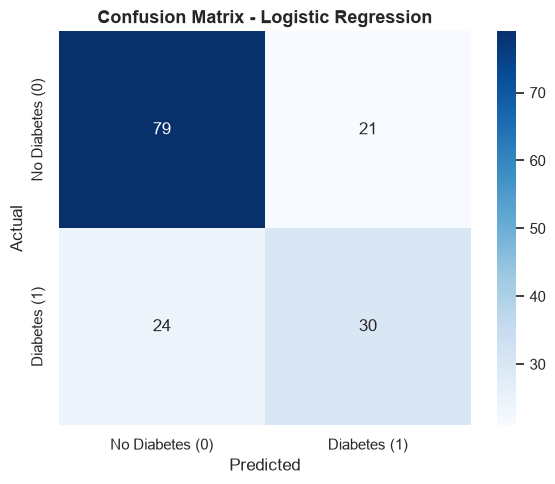

In [21]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['No Diabetes (0)', 'Diabetes (1)'],
    yticklabels=['No Diabetes (0)', 'Diabetes (1)']
)
plt.title('Confusion Matrix - Logistic Regression', fontsize=13, fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig(f'{output_dir}/07_confusion_matrix.png', dpi=300)
plt.show()
plt.close()

<Figure size 600x600 with 0 Axes>

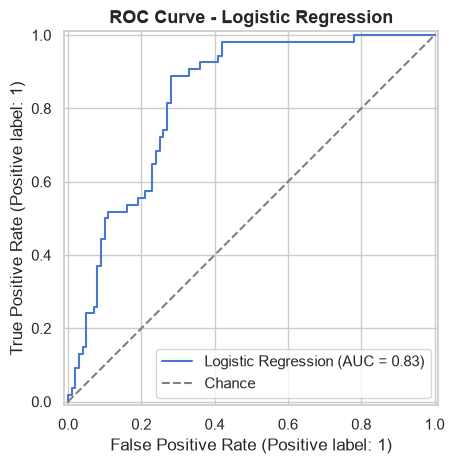

In [22]:
plt.figure(figsize=(6, 6))
RocCurveDisplay.from_predictions(y_test, y_proba, name='Logistic Regression')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance')
plt.title('ROC Curve - Logistic Regression', fontsize=13, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig(f'{output_dir}/08_roc_curve.png', dpi=300)
plt.show()
plt.close()

In [23]:
print("2. 5-Fold Stratified Cross-Validation (on training set)")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
print(f"ROC-AUC per fold: {np.round(cv_scores, 3)}")
print(f"Mean ROC-AUC: {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})\n")

2. 5-Fold Stratified Cross-Validation (on training set)
ROC-AUC per fold: [0.876 0.872 0.892 0.876 0.841]
Mean ROC-AUC: 0.872 (+/- 0.017)



In [24]:
print("3. Feature Coefficients (standardized features, log-odds scale)")
coef_df = pd.DataFrame({
    'Feature': features,
    'Coefficient': model.named_steps['clf'].coef_[0]
}).sort_values('Coefficient', key=abs, ascending=False)
print(coef_df.round(3).to_string(index=False), "\n")

3. Feature Coefficients (standardized features, log-odds scale)
                 Feature  Coefficient
                 Glucose        0.935
                 Insulin        0.614
                     BMI        0.466
             Pregnancies        0.337
           SkinThickness        0.295
DiabetesPedigreeFunction        0.175
                     Age        0.160
           BloodPressure       -0.004 



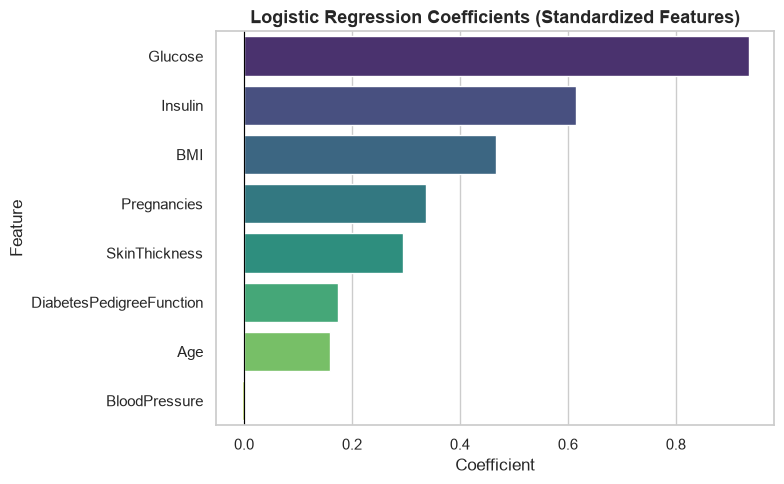

In [25]:
plt.figure(figsize=(8, 5))
sns.barplot(
    data=coef_df, x='Coefficient', y='Feature',
    hue='Feature', palette='viridis', legend=False
)
plt.title('Logistic Regression Coefficients (Standardized Features)', fontsize=13, fontweight='bold')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig(f'{output_dir}/09_coefficients.png', dpi=300)
plt.show()
plt.close()

In [26]:
print(f"Results table saved to 'report/model_results.csv'")
print(f"Figures saved to '{output_dir}/'")

Results table saved to 'report/model_results.csv'
Figures saved to '../report/figures/'
